# US RIA Market Analysis for Nevis - Justin McBryan
**Source(s):**
- SEC monthly Form ADV Part 1A
- September 2021 to September 2026
- November 2026 for current firm details
- Additional Data pulled from the bulk archive filing (data not reflected in monthly summaries)

# 1. Executive Summary:

The quickest way for Nevis to gather as much market share as possible is by working with the largest and fastest growing RIAs in the US. This assessment is focused on identifying the best canditates for Nevis to focus efforts on. Below outlines each question asked and its intended purpose:


| # | Question | Why it matters to Nevis |
|---|---|---|
| Q1 | How many RIAs fall into each AUM segment? | Identify largest firms given enterprise focus & fast following firms for longer tail pipeline & implementation|
| Q2a | Who are the fastest-growing firms? | Accelerated growth indicates potential advisor capacity constraints & potential budget for technology investment |
| Q2b | Which firms are capacity-strained? | High AUM (and clients) per advisor means advisors are stretched with broad servicing requirements |
| Q3 | Which RIAs appear under-staffed? | AUM growing faster than headcount is the clearest case for capacity challenges |

In [ ]:
#@title
# RUNS THE WHOLE PIPELINE: download SEC files -> standardise -> firm table -> analysis engine -> 22 data checks.
# Explained in Section 8. Critical checks stop the notebook here, before any result is shown.

# ==================== SETTINGS ====================
import os, re, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = Path(os.environ.get("NEVIS_DATA_DIR", "data"))
RAW, CACHE, OUT = DATA_DIR / "raw", DATA_DIR / "cache", Path("outputs")
for p in (RAW, CACHE, OUT): p.mkdir(parents=True, exist_ok=True)
# SEC fair-access policy: automated requests must identify a name and contact email
SEC_USER_AGENT = os.environ.get("SEC_USER_AGENT", "Justin McBryan justin.mcbryan@useaffluence.com")


# ==================== STEP 1: DOWNLOAD AND READ THE SEC ROSTER FILES ====================
BASE = "https://www.sec.gov/files/investment/data/"
OLD, NEW = "information-about-registered-investment-advisers-and-exempt-reporting-advisers/", "information-about-registered-investment-advisers-exempt-reporting-advisers/"
SNAPSHOTS = {
    "2021-09": BASE + OLD + "ia090121.zip",
    "2022-09": BASE + OLD + "ia090122.zip",
    "2023-09": BASE + NEW + "ia090623.xlsx",
    "2024-09": BASE + NEW + "ia090324.xlsx",
    "2025-09": BASE + NEW + "ia09022025.xlsx",
    "2026-09": BASE + "other/" + NEW + "ia09012026-registered.zip",
    "2026-11": BASE + "other/" + NEW + "ia110226-registered.zip",
}

# --- Alternative source: local hard copies -----------------------------------------------------------------
# The seven files below were also downloaded manually from the SEC website on 2 Nov 2026 and kept as hard copies.
# If sec.gov ever blocks automated downloads, place those copies in data/raw/ with these exact filenames:
# fetch() uses any file already present and skips the download. In Colab, the copies can live in Google Drive:
#   from google.colab import drive; drive.mount("/content/drive")
#   DATA_DIR = Path("/content/drive/MyDrive/Nevis-RIA-Analysis/data"); RAW, CACHE = DATA_DIR / "raw", DATA_DIR / "cache"
# EXPECTED_FILES records each file's size and SHA-256 fingerprint so CHECK V0 can prove the data is byte-identical
# to what this analysis used (the SEC occasionally republishes files).
EXPECTED_FILES = {  # filename: (bytes, first 16 hex chars of SHA-256)
    "ia090121.zip": (3384454, "ccc12bc76e2bc151"),
    "ia090122.zip": (3565069, "01e4ec044edaa5bb"),
    "ia090623.xlsx": (19506755, "5a8f2d98f0b40a22"),
    "ia090324.xlsx": (20010116, "1bae7d25b6cc06ad"),
    "ia09022025.xlsx": (20547238, "977d83fdd67acdc4"),
    "ia09012026-registered.zip": (5326806, "2302e3ea00819b40"),
    "ia110226-registered.zip": (5351876, "f17a9012368124a1"),
    "adv-filing-data-20111105-20241231-part1.zip": (705052552, "2bd4630011aa4b1d"),
    "adv-filing-data-20111105-20241231-part2.zip": (428897563, "89aed93a2973a3bf"),
}
# Bulk Form ADV archive (all filings Nov 2011 - Dec 2024): source for custodians (Sched. D 5.K(3)),
# owners (Schedules A/B), successions (Sched. D 4), control persons (Sched. D 10.A) and full website lists (Sched. D 1.I)
BULK = {p: "https://www.sec.gov/files/adv-filing-data-20111105-20241231-" + p + ".zip" for p in ("part1", "part2")}

def fetch(url):
    path = RAW / url.split("/")[-1]
    if not path.exists():
        with requests.get(url, headers={"User-Agent": SEC_USER_AGENT}, timeout=600, stream=True) as r:
            if r.status_code == 403:
                raise RuntimeError(f"SEC refused {url} (403). Set SEC_USER_AGENT to 'Your Name your@email', or upload the file to {RAW}/ and rerun.")
            r.raise_for_status()
            with open(path, "wb") as fh:
                for chunk in r.iter_content(1 << 20): fh.write(chunk)
    return path

def read_snapshot(label, url):
    cache = CACHE / f"{label}.pkl"
    if cache.exists(): return pd.read_pickle(cache)
    path = fetch(url)
    if path.suffix == ".zip":
        with zipfile.ZipFile(path) as z:
            name = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
            df = pd.read_csv(z.open(name), encoding="latin-1", dtype=str, low_memory=False)
    else:
        df = pd.read_excel(path, dtype=str)
    df.columns = [str(c).strip() for c in df.columns]
    df.to_pickle(cache); return df

raw = {lab: read_snapshot(lab, url) for lab, url in SNAPSHOTS.items()}
sources_tbl = pd.DataFrame({lab: {"firms": len(d), "columns": d.shape[1]} for lab, d in raw.items()}).T


# ==================== STEP 1B: EXTRACT CUSTODIANS, OWNERSHIP AND WEBSITES FROM THE BULK ARCHIVE ====================
REF = DATA_DIR / "reference"; REF.mkdir(parents=True, exist_ok=True)
REF_FILES = {k: REF / f"{k}.csv" for k in ("custodians", "ownership", "websites")}

def build_reference():
    """Read the needed tables straight out of the two bulk zips and write three small extracts."""
    zips = {p: zipfile.ZipFile(fetch(u)) for p, u in BULK.items()}
    def table(part, name, **kw):
        member = next(n for n in zips[part].namelist() if n.split("/")[-1].startswith(name + "_2011"))
        return pd.read_csv(zips[part].open(member), encoding="latin-1", dtype=str, low_memory=False, **kw)
    base = table("part1", "IA_ADV_Base_A", usecols=["FilingID", "DateSubmitted", "1A", "1E1"]).rename(columns={"1E1": "crd", "1A": "legal_name"})
    base["date"] = pd.to_datetime(base.DateSubmitted, errors="coerce", format="mixed")
    base = base.dropna(subset=["crd", "date"])
    last = base.sort_values("date").groupby("crd").tail(1).set_index("FilingID")           # latest filing per firm
    on_last = lambda t: t[t.FilingID.isin(last.index)].assign(crd=lambda x: x.FilingID.map(last.crd), filing_date=lambda x: x.FilingID.map(last.date))

    # Custodians (Schedule D 5.K(3)), with names standardised to a canonical custodian
    k = on_last(table("part2", "IA_Schedule_D_5K3").set_axis(["FilingID", "custodian_legal", "custodian_business", "city", "state", "country",
                                                               "related_person", "bd_sec_number", "lei", "raum_at_custodian"], axis=1))
    k["raum_at_custodian"] = pd.to_numeric(k.raum_at_custodian.str.replace(",", "", regex=False), errors="coerce")
    CANON = [(r"SCHWAB|TD AMERITRADE", "Charles Schwab"), (r"FIDELITY|NATIONAL FINANCIAL SERV", "Fidelity"), (r"PERSHING", "Pershing (BNY)"),
             (r"BANK OF NEW YORK|\bBNY\b", "BNY"), (r"STATE STREET", "State Street"), (r"NORTHERN TRUST", "Northern Trust"),
             (r"J\.?\s?P\.?\s?MORGAN|JPMORGAN", "J.P. Morgan"), (r"GOLDMAN", "Goldman Sachs"), (r"MORGAN STANLEY", "Morgan Stanley"),
             (r"\bUBS\b", "UBS"), (r"WELLS FARGO", "Wells Fargo"), (r"MERRILL|BANK OF AMERICA|BOFA", "BofA / Merrill"), (r"CITIBANK|CITIGROUP|\bCITI\b", "Citi"),
             (r"\bU\.?\s?S\.? BANK", "U.S. Bank"), (r"RAYMOND JAMES", "Raymond James"), (r"\bLPL\b", "LPL Financial"), (r"INTERACTIVE BROKERS", "Interactive Brokers"),
             (r"ALTRUIST", "Altruist"), (r"APEX CLEARING|APEX FINTECH", "Apex"), (r"EDWARD (D\. )?JONES", "Edward Jones"),
             (r"AMERIPRISE|AMERICAN ENTERPRISE INVESTMENT", "Ameriprise"), (r"VANGUARD", "Vanguard"), (r"\bRBC\b|ROYAL BANK OF CANADA", "RBC"),
             (r"STIFEL", "Stifel"), (r"JANNEY", "Janney"), (r"BAIRD", "Baird"), (r"FIFTH THIRD", "Fifth Third"), (r"\bPNC\b", "PNC"),
             (r"TRUIST|SUNTRUST", "Truist"), (r"MATRIX TRUST", "Matrix Trust"), (r"\bBMO\b|BANK OF MONTREAL", "BMO"), (r"SEI PRIVATE TRUST|\bSEI\b", "SEI")]
    def canon(legal, business):
        txt = f"{legal} {business}".upper()
        return next((n for p, n in CANON if re.search(p, txt)), str(business or legal).strip().title())
    k["custodian"] = [canon(a, b) for a, b in zip(k.custodian_legal, k.custodian_business)]
    k["canonical"] = k.custodian.isin({n for _, n in CANON})
    k.drop(columns=["FilingID", "lei"]).to_csv(REF_FILES["custodians"], index=False)

    # Ownership & control (Schedules A/B: direct and indirect owners; Schedule D 4: successions)
    ab = on_last(table("part1", "IA_Schedule_A_B"))
    ab["acquired"] = pd.to_datetime(ab["Status Acquired"], format="%m/%Y", errors="coerce")
    ctrl_owner = ab["Control Person"].eq("Y") & (ab["Ownership Code"].isin(["C", "D", "E"]) | ab.Schedule.eq("B"))   # 25%+ owners and their parents
    new = ab[ctrl_owner & ab["DE/FE/I"].isin(["DE", "FE"]) & (ab.acquired >= "2020-01-01")]                     # entity that took control since 2020
    SPONSOR = r"\bL\.?\s?P\.?\b|PARTNERS|EQUITY|INVESTORS|AGGREGATOR|CO-?INVEST|\bFUND\b|CAPITAL PARTNERS|ASSOCIATES [IVX]+"
    o = pd.DataFrame(index=pd.Index(last.crd.unique(), name="crd"))
    o["new_controlling_entity_since_2020"] = o.index.isin(new.crd)
    # Sponsor = new controlling entity whose name looks like a fund/partnership AND shares no distinctive word with the
    # adviser's own legal name (which would make it an internal holding company, e.g. "The Jones Financial Companies, L.L.L.P.")
    GENERIC = {"llc", "inc", "lp", "llp", "ltd", "the", "and", "group", "holdings", "holding", "capital", "management", "partners",
               "wealth", "financial", "advisors", "advisers", "investment", "investments", "company", "corp", "services", "trust", "fund"}
    toks = lambda n: {t for t in re.findall(r"[a-z0-9]+", str(n).lower()) if len(t) >= 3 and t not in GENERIC}
    new = new.assign(firm_legal=new.FilingID.map(last.legal_name))
    is_sponsor = new["Full Legal Name"].str.upper().str.contains(SPONSOR, regex=True, na=False) & \
                 [not (toks(a) & toks(b)) for a, b in zip(new["Full Legal Name"], new.firm_legal)]
    o["likely_pe_sponsor_owner"] = o.index.isin(new[is_sponsor].crd)
    o["sponsor_names"] = new[is_sponsor].groupby("crd")["Full Legal Name"].apply(lambda s: "; ".join(sorted(set(s))[:3]))
    o["new_controlling_entities"] = new.groupby("crd")["Full Legal Name"].apply(lambda s: "; ".join(sorted(set(s))[:3]))
    o["control_acquired_date"] = new.groupby("crd").acquired.max().dt.strftime("%Y-%m")
    o["ownership_layers"] = ab[ab.Schedule.eq("B")].groupby("crd").size()
    d4 = table("part2", "IA_Schedule_D_4").merge(base[["FilingID", "crd", "date"]], on="FilingID")
    o["successions_since_2020"] = d4[d4.date >= "2020-01-01"].groupby("crd").size()
    o["bulk_filing_date"] = last.set_index("crd").date.dt.strftime("%Y-%m-%d")
    o.fillna({"ownership_layers": 0, "successions_since_2020": 0}).to_csv(REF_FILES["ownership"])

    # Full website list (Schedule D 1.I)
    w = on_last(table("part1", "IA_Schedule_D_1I"))
    w.groupby("crd").Website.apply(lambda s: " | ".join(s.dropna().str.strip())).rename("websites").to_csv(REF_FILES["websites"])

# Rebuild if any extract is missing or was built by an older version of this notebook (schema check)
REF_SCHEMA = {"custodians": {"crd", "custodian", "canonical", "raum_at_custodian"},
              "ownership": {"crd", "new_controlling_entity_since_2020", "likely_pe_sponsor_owner", "sponsor_names", "successions_since_2020"},
              "websites": {"crd", "websites"}}
stale = lambda k: not REF_FILES[k].exists() or not REF_SCHEMA[k] <= set(pd.read_csv(REF_FILES[k], nrows=0).columns)
if any(stale(k) for k in REF_FILES):
    build_reference()
ref = {k: pd.read_csv(f, dtype={"crd": str}) for k, f in REF_FILES.items()}
ref["ownership"] = ref["ownership"].set_index("crd")
ref_rows = {k: f"{len(v):,} rows" for k, v in ref.items()}


# ==================== STEP 2: STANDARDISE FIELDS ====================
CLIENT_TYPES = list("abcdefghijklmn")
SOCIAL = re.compile(r"linkedin|facebook|twitter|(^|\.)x\.com$|instagram|youtube|tiktok|vimeo|spotify|yelp|pinterest|"
                    r"medium\.com|podcasts\.apple|podbean|threads\.net|bsky|substack|flickr|goo\.gl|bit\.ly|linktr\.ee|douyin|weibo|wechat|glassdoor|indeed\.com|jobs|careers|amazon\.com|wordpress\.com|soundcloud|iheart|apple\.com|blogspot", re.I)

def num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")

def domain(w):
    if not isinstance(w, str) or not w.strip(): return None
    d = re.sub(r"^https?://", "", w.strip().lower()).split("/")[0].split("?")[0]
    d = re.sub(r"^www\d?\.", "", d)
    return None if (SOCIAL.search(d) or "." not in d) else d

def first_present(r, cols):
    out = pd.Series(np.nan, index=r.index, dtype=object)
    for c in cols:
        if c in r: out = out.fillna(r[c].str.strip().replace("", np.nan))
    return out

def standardise(r, label):
    d = pd.DataFrame({
        "crd": r["Organization CRD#"].str.strip(),
        "sec_number": r["SEC#"].str.strip(),
        "firm_name": r["Primary Business Name"].str.strip(),
        "city": r["Main Office City"].str.strip().str.title(),
        "state": r["Main Office State"].str.strip(),
        # Main office country; the SEC blanks some main-office addresses, so fall back to mailing / organisation country
        "country": first_present(r, ["Main Office Country", "Mail Office Country", "3C-Country"]),
        "website_raw": r["Website Address"],
        "filing_date": pd.to_datetime(r["Latest ADV Filing Date"], errors="coerce", format="mixed"),
        "aum": num(r["5F(2)(c)"]),
        "employees": num(r["5A"]),
        "advisors": num(r["5B(1)"]),
        "iars": num(r["5B(3)"]),
    })
    counts = pd.concat([num(r[f"5D({t})(1)"]) for t in CLIENT_TYPES if f"5D({t})(1)" in r], axis=1)
    few = pd.concat([r[f"5D({t})(2)"].notna() for t in CLIENT_TYPES if f"5D({t})(2)" in r], axis=1)
    d["clients"] = counts.sum(axis=1, min_count=1).fillna(0) + 2.5 * few.sum(axis=1)
    retail = num(r["5D(a)(3)"]).fillna(0) + num(r["5D(b)(3)"]).fillna(0)
    d["retail_aum_share"] = np.where(d.aum > 0, retail / d.aum, np.nan)
    d["financial_planning"] = r["5G(1)"].eq("Y")
    d["broker_dealer"] = r["6A(1)"].eq("Y")              # firm is itself a broker-dealer (wirehouse / IBD dual registrant)
    d["succession"] = r["4A"].eq("Y") if "4A" in r else False
    d["snapshot"], d["year"] = label, int(label[:4])
    return d

std = {lab: standardise(r, lab) for lab, r in raw.items()}
panel = pd.concat([std[l] for l in std if l.endswith("-09")], ignore_index=True)


# ==================== STEP 3: FIX WEBSITES ====================
order = ["2026-11", "2026-09", "2025-09", "2024-09", "2023-09", "2022-09", "2021-09"]
STOP = {"llc", "inc", "lp", "llp", "ltd", "the", "and", "group", "capital", "management", "advisors", "advisers", "advisory",
        "wealth", "financial", "partners", "investment", "investments", "asset", "services", "company", "corp", "corporation", "trust"}
def name_tokens(name):
    toks = [t for t in re.findall(r"[a-z0-9]+", str(name).lower()) if len(t) >= 3 and t not in STOP]
    return toks or [t for t in re.findall(r"[a-z0-9]+", str(name).lower()) if len(t) >= 4]

names = std["2026-11"].set_index("crd").firm_name.combine_first(std["2026-09"].set_index("crd").firm_name)
cands = {}                     # crd -> list of (source, domain), most authoritative/recent first
for c, sites in zip(ref["websites"].crd, ref["websites"].websites.fillna("")):   # Schedule D 1.I: every address the firm lists
    for site in sites.split(" | "):
        dmn = domain(site)
        if dmn: cands.setdefault(c, []).append(("sched-1I", dmn))
for lab in order:
    for c, w in zip(std[lab].crd, std[lab].website_raw):
        dmn = domain(w)
        if dmn: cands.setdefault(c, []).append((lab, dmn))

rows = []
for c, lst in cands.items():
    toks = name_tokens(names.get(c, ""))
    match = [(lab, d) for lab, d in lst if any(t in d.replace("-", "") for t in toks)]
    roster = [(lab, d) for lab, d in lst if lab != "sched-1I"]
    lab, d = (match or roster or lst)[0]
    if match:   # trim advisor/team sub-domains, e.g. bridgemark.apollonwealth.com -> apollonwealth.com
        parts = d.split("."); root = ".".join(parts[-3:] if parts[-2] in {"co", "com", "org"} and len(parts) > 2 else parts[-2:])
        if any(t in root.replace("-", "") for t in toks): d = root
    src = ("Schedule D 1.I (bulk, ≤2024)" if lab == "sched-1I" else "current filing" if lab == "2026-11" else f"earlier filing ({lab[:4]})")
    rows.append((c, f"www.{d}", src, "name match" if match else "unverified (no name match)"))
web = pd.DataFrame(rows, columns=["crd", "website", "website_source", "website_confidence"])
# Analyst-verified overrides (web search, Nov 2026) for shortlisted $10B+ targets and the brief's example firm,
# where the roster only ever showed social profiles or an individual advisor's site
VERIFIED = {"119290": "www.beaconpointe.com",      # Beacon Pointe Advisors
            "Pathstone": "www.pathstone.com", "Focus Partners Wealth": "www.focuspartners.com",
            "CWM, LLC": "www.carsonwealth.com", "Osaic Wealth": "www.osaic.com", "Fisher Investments": "www.fisherinvestments.com",
            "Cetera Investment Advisers": "www.cetera.com", "NewEdge Advisors": "www.newedgewealth.com",
            "105674": "www.clearstead.com"}            # Clearstead (roster shows a podcast page)
for key, site in VERIFIED.items():
    crds = [key] if key.isdigit() else names[names.str.upper().str.startswith(key.upper())].index.tolist()
    for c in crds:
        web = pd.concat([web[web.crd != c], pd.DataFrame([[c, site, "analyst-verified (web search)", "verified"]], columns=web.columns)])


# ==================== STEP 4: BUILD THE FIRM TABLE ====================
ident_cols = ["crd", "sec_number", "firm_name", "city", "state", "country"]
ident = pd.concat([std["2026-11"][ident_cols], std["2026-09"][ident_cols]]).drop_duplicates("crd")
ident = ident.merge(web, on="crd", how="left")
ident["website_source"] = ident.website_source.fillna("social profile only")
ident["website_confidence"] = ident.website_confidence.fillna("none")

metrics = ["crd", "year", "filing_date", "aum", "clients", "employees", "advisors", "iars", "retail_aum_share", "financial_planning", "broker_dealer", "succession"]
firm_year = panel[metrics].merge(ident, on="crd", how="left")
firm_year["fiscal_year"] = firm_year.year - 1
firm_year["avg_aum_per_client"] = np.where(firm_year.clients > 0, firm_year.aum / firm_year.clients, np.nan)
firm_year["aum_per_advisor"] = np.where(firm_year.advisors > 0, firm_year.aum / firm_year.advisors, np.nan)
firm_year["clients_per_advisor"] = np.where(firm_year.advisors > 0, firm_year.clients / firm_year.advisors, np.nan)
# Target RIA (Nevis ICP): US-headquartered, mostly individual/HNW AUM, offers financial planning,
# and a client load per advisor consistent with relationship-based advice (excludes robo, TAMP and model-delivery platforms).
# Broker-dealer channels that don't tick 5.G(1) (e.g. Merrill) qualify via a large registered advisor force (100+ IARs).
# (Column keeps its original name, wealth_manager, so downstream code is unchanged.)
firm_year["wealth_manager"] = ((firm_year.retail_aum_share >= 0.5) & (firm_year.country == "United States") & (firm_year.clients_per_advisor <= 500)
                               & (firm_year.financial_planning | (firm_year.broker_dealer & (firm_year.iars >= 100))))
firm_year["channel"] = np.where(firm_year.broker_dealer, "Dual-registered (broker-dealer)", "Independent RIA")

cols = ["sec_number", "firm_name", "website", "website_source", "website_confidence", "city", "state", "aum", "clients", "avg_aum_per_client",
        "employees", "advisors", "iars", "aum_per_advisor", "clients_per_advisor", "retail_aum_share", "wealth_manager", "channel", "filing_date", "fiscal_year", "year", "crd"]
firm_year = firm_year[cols].sort_values(["year", "aum"], ascending=[True, False])
firm_year.to_csv(OUT / "ria_firm_year_table.csv", index=False)
latest = firm_year[firm_year.year == 2026].copy()


# ==================== STEPS 5-6: ANALYSIS ENGINE (ALL METRICS) ====================
# ===================== ANALYSIS ENGINE =====================
# Every metric used in Sections 2-6 is computed here, once. Presentation cells only display these objects.

# --- Q1: market segments on FY2025 AUM ---
BINS = [-np.inf, 1e9, 10e9, 50e9, np.inf]
LABELS = ["<$1B", "$1B-$10B", "$10B-$50B", ">$50B"]
latest["segment"] = pd.cut(latest.aum, BINS, labels=LABELS, right=False)
seg_map = latest.set_index("crd").segment
seg = latest.groupby("segment", observed=False).agg(
    RIAs=("crd", "count"), wealth_managers=("wealth_manager", "sum"),
    total_aum_trn=("aum", lambda x: x.sum() / 1e12), median_aum_bn=("aum", lambda x: x.median() / 1e9),
    median_advisors=("advisors", "median"), median_clients=("clients", "median"))
seg["share_of_firms"] = seg.RIAs / seg.RIAs.sum()
seg["share_of_aum"] = seg.total_aum_trn / seg.total_aum_trn.sum()

# --- Growth windows (Q2a, Q3) ---
MIN_START = {"<$1B": 100e6, "$1B-$10B": 200e6, "$10B-$50B": 2e9, ">$50B": 10e9}
p = firm_year.pivot_table(index="crd", columns="year", values=["aum", "advisors"])
succ = panel.pivot_table(index="crd", columns="year", values="succession", aggfunc="max")

def window(h, end=2026):
    s0 = end - h
    w = pd.DataFrame({"aum_start": p["aum"][s0], "aum_end": p["aum"][end],
                      "adv_start": p["advisors"][s0], "adv_end": p["advisors"][end]}).dropna(subset=["aum_start", "aum_end"])
    w["segment"] = seg_map.reindex(w.index).values
    w = w[(w.aum_start >= w.segment.astype(str).map(MIN_START)) & (w.aum_end > 0)]
    w["aum_cagr"] = (w.aum_end / w.aum_start) ** (1 / h) - 1
    ok = (w.adv_start >= 3) & (w.adv_end >= 1)
    w["advisor_cagr"] = np.where(ok, (w.adv_end / w.adv_start) ** (1 / h) - 1, np.nan)
    w["staffing_gap"] = w.aum_cagr - w.advisor_cagr
    w["excess_growth"] = w.aum_cagr - w.groupby("segment", observed=False).aum_cagr.transform("median")
    yrs = list(range(s0, end + 1))
    a, v = p["aum"].reindex(w.index)[yrs], p["advisors"].reindex(w.index)[yrs]
    aum_jump = (a / a.shift(axis=1)).iloc[:, 1:].max(axis=1)
    adv_jump = (v / v.shift(axis=1).where(v.shift(axis=1) >= 3)).iloc[:, 1:].max(axis=1)
    succ_w = succ.reindex(w.index)[[y for y in yrs[1:] if y in succ.columns]].fillna(False).astype(bool).any(axis=1)
    adv_drop = (v / v.shift(axis=1).where(v.shift(axis=1) >= 3)).iloc[:, 1:].min(axis=1)
    w["inorganic_flag"] = (aum_jump > 2.5).values | (adv_jump > 2).fillna(False).values | succ_w.values
    w["headcount_reclass"] = (adv_drop < 0.4).fillna(False).values   # >60% advisor drop in a year = reporting change, not attrition
    w = w.join(ident.set_index("crd")[["firm_name", "website", "website_confidence", "city", "state", "country"]])
    w = w.join(latest.set_index("crd")[["wealth_manager", "channel", "aum_per_advisor", "clients_per_advisor"]])
    w["wealth_manager"] = w.wealth_manager.fillna(False).astype(bool)
    w["horizon"] = f"{h}y"
    return w.reset_index()

win = {h: window(h) for h in (1, 3, 5)}
window_summary = pd.DataFrame({f"{h}y": {"firms in window": len(w), "flagged inorganic": int(w.inorganic_flag.sum()),
                        "median AUM CAGR %": 100 * w.aum_cagr.median(), "median advisor CAGR %": 100 * w.advisor_cagr.median()}
              for h, w in win.items()}).T

# --- Formatting and ranking helpers ---
def fmt(df):
    out = df.copy()
    for c in ["aum_start", "aum_end", "aum"]:
        if c in out: out[c] = (out[c] / 1e9).round(2)
    if "aum_per_advisor" in out: out["aum_per_advisor"] = (out["aum_per_advisor"] / 1e6).round(0)
    for c in ["aum_cagr", "advisor_cagr", "staffing_gap", "excess_growth", "retail_aum_share"]:
        if c in out: out[c] = (out[c] * 100).round(1)
    return out.rename(columns={"aum_start": "AUM start $B", "aum_end": "AUM end $B", "aum": "AUM $B", "aum_cagr": "AUM CAGR %",
                               "advisor_cagr": "Advisor CAGR %", "staffing_gap": "Gap (pp)", "excess_growth": "vs seg. median (pp)",
                               "aum_per_advisor": "AUM/advisor $M", "retail_aum_share": "Retail AUM %"})

def top_by_segment(df, metric, n=10, wealth_only=False, cols=None, organic=False):
    d = df[df.wealth_manager.fillna(False).astype(bool)] if wealth_only else df
    if organic: d = d[~d.inorganic_flag & ~d.headcount_reclass]
    d = d.dropna(subset=[metric]).sort_values(metric, ascending=False)
    return d.groupby("segment", observed=True, group_keys=False).head(n)[["segment"] + cols]

# --- Q2a: fastest growing ---
G = ["firm_name", "channel", "state", "aum_start", "aum_end", "aum_cagr", "excess_growth", "wealth_manager"]
fast = {h: top_by_segment(win[h], "aum_cagr", cols=G, organic=True) for h in (1, 3, 5)}
fast_wm = {h: top_by_segment(win[h], "aum_cagr", wealth_only=True, cols=G, organic=True) for h in (1, 3, 5)}
inorganic_wm = top_by_segment(win[3][win[3].inorganic_flag], "aum_cagr", n=5, wealth_only=True, cols=G + ["adv_start", "adv_end"])

# --- Q2b: capacity-strained (FY2025, firms with 3+ advisors) ---
cap = latest[(latest.advisors >= 3) & (latest.aum > 0)].copy()
cap["wealth_manager"] = cap.wealth_manager.fillna(False).astype(bool)
C = ["firm_name", "channel", "state", "aum", "advisors", "iars", "aum_per_advisor", "clients_per_advisor", "retail_aum_share"]
cap_all = top_by_segment(cap, "aum_per_advisor", cols=C)
cap_wm = top_by_segment(cap, "aum_per_advisor", wealth_only=True, cols=C)
cap_medians = (cap[cap.wealth_manager].groupby("segment", observed=True)[["aum_per_advisor", "clients_per_advisor"]].median()
               .assign(aum_per_advisor=lambda x: x.aum_per_advisor / 1e6).rename(columns={"aum_per_advisor": "median AUM/advisor $M"}))

# --- Q3: under-staffed ---
S = ["firm_name", "channel", "state", "aum_end", "aum_cagr", "advisor_cagr", "staffing_gap", "adv_start", "adv_end", "wealth_manager"]
gap = {h: top_by_segment(win[h], "staffing_gap", cols=S, organic=True) for h in (1, 3, 5)}
gap_wm = {h: top_by_segment(win[h], "staffing_gap", wealth_only=True, cols=S, organic=True) for h in (1, 3, 5)}
w3 = win[3][win[3].wealth_manager & ~win[3].inorganic_flag & ~win[3].headcount_reclass & win[3].advisor_cagr.notna() & (win[3].aum_end >= 1e9)]

# --- Section 6: combined Nevis target score ---
t = win[3][win[3].wealth_manager & win[3].staffing_gap.notna() & win[3].aum_per_advisor.notna()
           & (win[3].adv_end >= 5) & (win[3].country == "United States")].copy()
for m in ["aum_cagr", "aum_per_advisor", "staffing_gap"]:
    t[f"{m}_pctl"] = t.groupby("segment", observed=True)[m].rank(pct=True)
t["nevis_score"] = t[["aum_cagr_pctl", "aum_per_advisor_pctl", "staffing_gap_pctl"]].mean(axis=1) * 100
T = ["firm_name", "channel", "website", "website_confidence", "city", "state", "aum_end", "aum_cagr", "aum_per_advisor", "clients_per_advisor", "staffing_gap", "adv_end", "inorganic_flag", "nevis_score"]
targets = (t.sort_values("nevis_score", ascending=False).groupby("segment", observed=True, group_keys=False).head(10)
           .sort_values(["segment", "nevis_score"], ascending=[False, False])[["segment"] + T])

# --- 6.1 custodians and 6.2 ownership change (bulk extracts joined to FY2025 firms) ---
wmask = latest.wealth_manager.fillna(False).astype(bool)
cust = ref["custodians"].merge(latest[["crd", "firm_name", "segment", "aum", "channel"]].assign(wealth_manager=wmask.values), on="crd")
def custodian_share(mask_df):
    firms = latest[mask_df]; cs = cust[cust.crd.isin(firms.crd)]
    out = (cs.groupby("custodian").agg(firms=("crd", "nunique"), aum_held_bn=("raum_at_custodian", lambda x: x.sum() / 1e9))
             .assign(share_of_firms=lambda x: x.firms / len(firms)).sort_values("firms", ascending=False))
    return out, cs.crd.nunique() / max(len(firms), 1), len(firms)
cust_views = {"All RIAs >$50B": latest.aum >= 50e9, "Target RIAs >$50B": (latest.aum >= 50e9) & wmask,
              "Target RIAs $10B-$50B": (latest.segment == "$10B-$50B") & wmask, "Target RIAs $1B-$10B": (latest.segment == "$1B-$10B") & wmask}
cust_tables = {k: custodian_share(m) for k, m in cust_views.items()}
# Analyst-verified exclusions: these filings show an internal holding-company restructure, not a sale to a new owner
# (validated against external sources), so they are not ownership-change signals.
INTERNAL_RESTRUCTURE = {"149777": "Morgan Stanley: new controlling entity is an internal Morgan Stanley company",
                        "250": "Edward Jones: JFC Holding / The Jones Financial Companies are the firm's own partnership structure"}
ref["ownership"].loc[ref["ownership"].index.isin(list(INTERNAL_RESTRUCTURE)), ["new_controlling_entity_since_2020", "likely_pe_sponsor_owner"]] = False
own = latest[wmask & (latest.aum >= 1e9)].set_index("crd")[["firm_name", "channel", "state", "aum", "advisors", "segment"]].join(ref["ownership"])
own["ownership_change"] = own.new_controlling_entity_since_2020.fillna(False).astype(bool) | (own.successions_since_2020.fillna(0) > 0)
own_summary = own.groupby("segment", observed=True).agg(
    wealth_managers=("firm_name", "count"), ownership_change=("ownership_change", "mean"),
    new_controlling_entity=("new_controlling_entity_since_2020", "mean"), likely_pe_sponsor=("likely_pe_sponsor_owner", "mean"),
    any_succession=("successions_since_2020", lambda x: (x > 0).mean()))


# ==================== DATA CHECKS V0-V13 (DATA INTEGRITY) ====================
import hashlib
checks = []
def check(cid, name, passed, detail, critical=True):
    checks.append({"id": cid, "check": name, "result": "PASS" if passed else ("FAIL" if critical else "WARN"), "detail": detail})
    if critical and not passed:
        raise AssertionError(f"CHECK {cid} failed: {name} | {detail}")

# CHECK V0: file fingerprints (warning only: SEC may legitimately republish a file)
fp = {}
for fname, (size, sha) in EXPECTED_FILES.items():
    f = RAW / fname
    got = hashlib.sha256(f.read_bytes()).hexdigest()[:16] if f.exists() else None
    fp[fname] = (f.exists() and f.stat().st_size == size and got == sha)
check("V0", "Source files byte-identical to analysed versions", all(fp.values()),
      f"{sum(fp.values())}/{len(fp)} files match size + SHA-256", critical=False)

# CHECK V1: schema, i.e. every required Form ADV column present in every snapshot
REQUIRED = ["Organization CRD#", "SEC#", "Primary Business Name", "Main Office City", "Main Office State", "Website Address",
            "Latest ADV Filing Date", "5A", "5B(1)", "5B(3)", "5F(2)(a)", "5F(2)(b)", "5F(2)(c)", "5G(1)", "5D(a)(3)", "5D(b)(3)"] + \
           [f"5D({t})(1)" for t in CLIENT_TYPES]
missing = {lab: [c for c in REQUIRED if c not in r.columns] for lab, r in raw.items()}
check("V1", "All required Form ADV fields present in all 7 snapshots", not any(missing.values()),
      f"{len(REQUIRED)} fields × {len(raw)} files; missing: {({k: v for k, v in missing.items() if v}) or 'none'}")

# CHECK V2: completeness, i.e. plausible firm counts, rising year on year
n = {lab: len(r) for lab, r in raw.items()}
sep = [n[l] for l in sorted(n) if l.endswith("-09")]
check("V2", "Firm counts plausible (13k-20k) and rising each year", all(13_000 <= v <= 20_000 for v in n.values()) and sep == sorted(sep),
      " → ".join(f"{l[:4]}: {v:,}" for l, v in n.items() if l.endswith("-09")))

# CHECK V3: uniqueness, one row per firm per snapshot
dups = {lab: int(d.crd.duplicated().sum()) for lab, d in std.items()}
check("V3", "One row per CRD# in every snapshot", sum(dups.values()) == 0, f"duplicate CRDs: {sum(dups.values())}")

# CHECK V4: identifier format
sec_ok = min(d.sec_number.str.fullmatch(r"801-\d+").mean() for d in std.values())
crd_ok = min(d.crd.str.fullmatch(r"\d+").mean() for d in std.values())
check("V4", "SEC# = 801-XXXXX and CRD# numeric", sec_ok == 1 and crd_ok == 1, f"SEC# valid {sec_ok:.2%}, CRD# valid {crd_ok:.2%} (worst snapshot)")

# CHECK V5: numeric parsing, no populated value lost when converting text → number
fails = {}
for lab, r in raw.items():
    for col in ["5A", "5B(1)", "5B(3)", "5F(2)(a)", "5F(2)(b)", "5F(2)(c)"] + [f"5D({t})(1)" for t in CLIENT_TYPES if f"5D({t})(1)" in r]:
        populated = r[col].notna() & r[col].astype(str).str.strip().ne("")
        fails[(lab, col)] = int((populated & num(r[col]).isna()).sum())
check("V5", "Numeric fields parse without loss", sum(fails.values()) == 0,
      f"{len(fails)} field-snapshots checked; unparseable values: {sum(fails.values())}")

# CHECK V6: AUM identity (5.F(2)(a) + (b) = (c)), within $1 rounding
ident_ok = {lab: float(((num(r["5F(2)(a)"]).fillna(0) + num(r["5F(2)(b)"]).fillna(0) - num(r["5F(2)(c)"]).fillna(0)).abs() <= 1).mean())
            for lab, r in raw.items()}
check("V6", "Discretionary + non-discretionary AUM = total AUM", min(ident_ok.values()) >= 0.999,
      f"holds for {min(ident_ok.values()):.2%} of firms (worst snapshot)")

# CHECK V7: AUM by client type (5.D(x)(3)) sums to total AUM (5.F(2)(c)), within 1%
s7 = {}
for lab, r in raw.items():
    tot = num(r["5F(2)(c)"])
    parts = pd.concat([num(r[f"5D({t})(3)"]) for t in CLIENT_TYPES if f"5D({t})(3)" in r], axis=1).sum(axis=1)
    m = tot > 0
    s7[lab] = float(((parts[m] - tot[m]).abs() / tot[m] <= 0.01).mean())
check("V7", "Client-type AUM (5.D) sums to total AUM (5.F)", min(s7.values()) >= 0.98,
      f"within 1% for {min(s7.values()):.1%} of firms (worst snapshot)", critical=False)

# CHECK V8: no negative values
neg = int((panel[["aum", "clients", "employees", "advisors", "iars"]] < 0).sum().sum())
check("V8", "No negative AUM, clients or headcount", neg == 0, f"negative values: {neg}")

# CHECK V9: advisors ≤ employees (advisors are a subset of employees)
over = panel.advisors > panel.employees
check("V9", "Advisors ≤ employees", over.mean() < 0.01,
      f"{over.sum():,} firm-years ({over.mean():.2%}) report more advisors than employees; ratios still computed", critical=False)

# CHECK V10: reconciliation to SEC-published industry RAUM
r23 = panel.loc[panel.year == 2023, "aum"].sum() / 1e12
check("V10", "2023 total RAUM reconciles to SEC published (~$125T-$128T)", 120 <= r23 <= 135, f"computed ${r23:,.1f}T")

# CHECK V11: cross-year linkage by CRD#
ids = {y: set(panel.loc[panel.year == y, "crd"]) for y in sorted(panel.year.unique())}
link = {y: len(ids[y] & ids[y - 1]) / len(ids[y - 1]) for y in list(ids)[1:]}
check("V11", "≥85% of firms carry forward to the next year by CRD#", min(link.values()) >= 0.85,
      ", ".join(f"{y - 1}→{y}: {v:.1%}" for y, v in link.items()))

# CHECK V12: Sep vs Nov 2026, AUM should be (almost) unchanged because Item 5 updates annually
mm = std["2026-09"][["crd", "aum"]].merge(std["2026-11"][["crd", "aum"]], on="crd", suffixes=("_sep", "_nov"))
same = float((mm.aum_sep == mm.aum_nov).mean())
check("V12", "AUM identical Sep→Nov 2026 for most firms (annual-update design)", same >= 0.85,
      f"{same:.1%} of {len(mm):,} firms unchanged; differences are mid-year amendments", critical=False)

# CHECK V13: spot check vs IAPD public profile (Beacon Pointe Advisors, CRD 119290)
bp = std["2026-09"].set_index("crd").loc["119290"]
check("V13", "Beacon Pointe matches IAPD (AUM ≈ $54.9B, 440 advisors, Newport Beach CA)",
      abs(bp.aum / 1e9 - 54.87) < 0.1 and bp.advisors == 440 and bp.city == "Newport Beach" and bp.state == "CA",
      f"AUM ${bp.aum/1e9:,.2f}B, advisors {bp.advisors:.0f}, {bp.city}, {bp.state}")


# ==================== DATA CHECKS V14-V21 (CALCULATIONS) ====================
# CHECK V14: segment counts reconcile to universe
check("V14", "Segment counts sum to all FY2025 RIAs", int(seg.RIAs.sum()) == len(latest) == raw["2026-09"].shape[0],
      f"{int(seg.RIAs.sum()):,} = {len(latest):,} = {raw['2026-09'].shape[0]:,}")

# CHECK V15: no inf / impossible values in derived metrics
derived = pd.concat([latest[["avg_aum_per_client", "aum_per_advisor", "clients_per_advisor", "retail_aum_share"]].stack()] +
                    [w[["aum_cagr", "advisor_cagr", "staffing_gap"]].stack() for w in win.values()])
bad = int(np.isinf(derived).sum()); share_bad = int(((latest.retail_aum_share < 0) | (latest.retail_aum_share > 1.05)).sum())
check("V15", "No infinite values; retail AUM share within 0-100%", bad == 0, f"inf values: {bad}; retail share outside range: {share_bad} firms")

# CHECK V16: CAGR independently recomputed from raw source AUM for a random sample
raw_aum = {lab: num(r.set_index(r["Organization CRD#"].str.strip())["5F(2)(c)"]) for lab, r in raw.items() if lab.endswith("-09")}
ok16 = []
for h, w in win.items():
    for _, row in w.sample(min(200, len(w)), random_state=42).iterrows():
        a0, a1 = raw_aum[f"{2026 - h}-09"][row.crd], raw_aum["2026-09"][row.crd]
        ok16.append(abs((a1 / a0) ** (1 / h) - 1 - row.aum_cagr) < 1e-9)
check("V16", "CAGR reproduces from raw SEC values (600-firm sample)", all(ok16), f"{sum(ok16)}/{len(ok16)} match")

# CHECK V17: ranked lists obey their own filters
viol = 0
for h in (1, 3, 5):
    for lst in (fast[h], gap[h]):
        w = win[h].loc[lst.index]
        viol += int((w.inorganic_flag | w.headcount_reclass).sum())
        viol += int((w.aum_start < w.segment.astype(str).map(MIN_START)).sum())
check("V17", "Ranked lists exclude flagged firms and respect min starting AUM", viol == 0, f"rule violations: {viol}")

# CHECK V18: website data-quality transparency
wc = latest.website_confidence.value_counts(normalize=True)
check("V18", "Website confidence reported for every firm", latest.website_confidence.notna().all(),
      ", ".join(f"{k}: {v:.0%}" for k, v in wc.items()), critical=False)

# CHECK V19: classification, i.e. known asset managers excluded, known target RIAs (incl. wirehouses) included
AM = {"105958": "Vanguard", "108281": "Fidelity Mgmt & Research", "105247": "BlackRock Fund Advisors", "110885": "Capital Research",
      "104559": "PIMCO", "107038": "J.P. Morgan Inv. Mgmt", "107738": "Goldman Sachs Asset Mgmt", "105496": "T. Rowe Price"}
WM = {"119290": "Beacon Pointe", "7691": "Merrill", "149777": "Morgan Stanley", "250": "Edward Jones", "105348": "Creative Planning", "159289": "Focus Partners"}
isw = latest.set_index("crd").wealth_manager.fillna(False)
bad_am, bad_wm = [n for c, n in AM.items() if isw.get(c, False)], [n for c, n in WM.items() if not isw.get(c, False)]
check("V19", "Asset managers excluded and target RIAs/wirehouses included", not bad_am and not bad_wm,
      f"{len(AM)} asset managers excluded, {len(WM)} target RIAs included; misclassified: {bad_am + bad_wm or 'none'}")

# CHECK V20: bulk extracts link to FY2025 firms
cov = latest.loc[wmask & (latest.aum >= 1e9), "crd"].isin(ref["ownership"].index).mean()
check("V20", "Bulk-archive extracts cover ≥95% of $1B+ target RIAs", cov >= 0.95, f"{cov:.1%} of FY2025 $1B+ target RIAs found in the Dec 2024 bulk archive")

# CHECK V21: custodian names standardised for the firms we analyse
mapped = cust[cust.wealth_manager & (cust.aum >= 1e9)]
share_mapped = (mapped.raum_at_custodian * mapped.canonical).sum() / mapped.raum_at_custodian.sum()
check("V21", "≥90% of $1B+ target-RIA custodian AUM mapped to a standard name", share_mapped >= 0.9, f"{share_mapped:.1%} of custodian-held AUM mapped", critical=False)

summary = pd.DataFrame(checks).set_index("id")


# ==================== PRESENTATION HELPERS (TABLE FORMATTING) ====================
import re
from IPython.display import HTML, display
PLAIN = {"segment": "Segment", "firm_name": "Firm", "channel": "Channel", "state": "State", "city": "City", "website": "Website",
         "aum": "AUM ($B)", "aum_start": "AUM at start ($B)", "aum_end": "AUM FY2025 ($B)", "aum_cagr": "AUM growth / yr",
         "advisor_cagr": "Advisor growth / yr", "staffing_gap": "Staffing gap", "excess_growth": "vs segment median",
         "aum_per_advisor": "AUM per advisor ($M)", "clients_per_advisor": "Clients per advisor", "advisors": "Advisors",
         "adv_start": "Advisors at start", "adv_end": "Advisors FY2025", "nevis_score": "Nevis score",
         "new_controlling_entity_since_2020": "New owner since 2020", "likely_pe_sponsor_owner": "Likely PE-backed (est.)",
         "control_acquired_date": "Control acquired", "new_controlling_entities": "New controlling owner(s)"}
CHANNEL_SHORT = {"Dual-registered (broker-dealer)": "Dual-registered (BD)"}
BN, PCT, PTS = {"aum", "aum_start", "aum_end"}, {"aum_cagr", "advisor_cagr"}, {"staffing_gap", "excess_growth"}
INT = {"advisors", "adv_start", "adv_end", "clients_per_advisor", "nevis_score", "aum_per_advisor"}
SUFFIX = re.compile(r"[,\s]+(LLC|L\.L\.C\.?|L\.L\.L\.P\.?|LLP|L\.P\.?|LP|INC\.?|INCORPORATED|CORP\.?|CORPORATION|LTD\.?)\.?$", re.I)
CAMEL = {"Newedge": "NewEdge", "Cliftonlarsonallen": "CliftonLarsonAllen", "Onepoint": "OnePoint", "Bfg": "BFG"}
KEEP_UPPER = {"CWM", "MML", "BFG", "IEQ", "MAI", "RWA", "PGI", "EP", "SCS", "AE", "RBC", "MWA", "PAG", "CIBC", "BBR", "UBS", "LPL", "PNC", "HSBC", "USA", "II", "III", "IV", "CPA", "CPAS", "NY", "SEI", "BNY", "WWM"}
def nice_name(s):
    """SEC names are filed in capitals with legal suffixes: show 'Cresset Asset Management' rather than 'CRESSET ASSET MANAGEMENT, LLC'."""
    s = str(s).split(";")[0].strip()
    for _ in range(2): s = SUFFIX.sub("", s).strip().rstrip(",")
    words = []
    for w in s.split():
        core = re.sub(r"[^A-Za-z]", "", w)
        words.append(w if core.upper() in KEEP_UPPER or (core and not re.search(r"[AEIOUY]", core.upper()) and len(core) <= 4) else w.capitalize())
    return " ".join(CAMEL.get(w, w) for w in words).replace("'S ", "'s ")
TEXT_COLS = {"segment", "firm_name", "channel", "state", "city", "website", "new_controlling_entities", "control_acquired_date",
             "new_controlling_entity_since_2020", "likely_pe_sponsor_owner"}
CAPTION_CSS = [{"selector": "td", "props": "white-space: nowrap"},{"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: 600; font-size: 1.05em; padding: 4px 0 8px"}]

def show(df, caption, cols=None, n=None, sort=None):
    """Display a ranked table: plain-English headers, consistent number formats, largest segment first."""
    d = df.copy()
    if sort: d = d.sort_values(["segment", sort], ascending=[False, False]) if "segment" in d else d.sort_values(sort, ascending=False)
    if n is not None: d = d.groupby("segment", observed=True, group_keys=False, sort=False).head(n) if "segment" in d else d.head(n)
    if cols: d = d[cols]
    if "segment" in d: d["segment"] = d.segment.astype(str)
    if "firm_name" in d: d["firm_name"] = d.firm_name.map(nice_name)
    if "channel" in d: d["channel"] = d.channel.replace(CHANNEL_SHORT)
    for c in BN & set(d): d[c] = d[c] / 1e9
    if "aum_per_advisor" in d: d["aum_per_advisor"] = d.aum_per_advisor / 1e6
    for c in ["new_controlling_entity_since_2020", "likely_pe_sponsor_owner"]:
        if c in d: d[c] = d[c].map({True: "Yes"}).fillna("")
    if "new_controlling_entities" in d: d["new_controlling_entities"] = d.new_controlling_entities.fillna("").astype(str).str.slice(0, 70)
    f = {}
    for c in d:
        if c in BN: f[c] = "{:,.1f}"
        elif c in PCT: f[c] = "{:.0%}"
        elif c in PTS: f[c] = lambda x: f"{x * 100:+.0f} pts"
        elif c in INT: f[c] = "{:,.0f}"
    text = [PLAIN.get(c, c) for c in d if c in TEXT_COLS]
    left = {c: [{"selector": "th", "props": "text-align: left"}] for c in text}
    return (d.rename(columns=PLAIN).style.hide(axis="index").set_caption(caption).set_table_styles(CAPTION_CSS)
             .set_table_styles(left, overwrite=False).set_properties(subset=text, **{"text-align": "left"})
             .format({PLAIN.get(k, k): v for k, v in f.items()}, na_rep="–"))

def collapsible(label, *tables):
    """Fold secondary tables into a click-to-expand section."""
    display(HTML(f"<details><summary><b>{label}</b></summary>" + "<br>".join(t.to_html() for t in tables) + "</details>"))

def styled(df, caption, fmt=None):
    return df.style.set_caption(caption).set_table_styles(CAPTION_CSS).format(fmt or {}, na_rep="–")


# 2. **How many RIAs fall into each AUM market segment?**

*Segments use each firm's FY2025 total AUM from the SEC's September 2026 file.*

**Key takeaways**

**RIAs by AUM segment (FY2025)**
* **Under \$1B:** 11,756 RIAs (69% of firms, 2% of AUM), of which **5,806** are target RIAs
* **\$1B–\$10B:** 4,023 RIAs (23% of firms, 7% of AUM), of which **1,193** are target RIAs
* **\$10B–\$50B:** 938 RIAs (5% of firms, 12% of AUM), of which **122** are target RIAs
* **Over \$50B:** 432 RIAs (3% of firms, 79% of AUM), of which **44** are target RIAs

**Definitions**
* **RIA (Registered Investment Adviser):** a firm registered with the SEC to give investment advice. All 17,149 firms here are RIAs, including asset managers and fund advisers as well as firms that advise individuals.
* **Target RIA:** an RIA Nevis would sell to: US-headquartered, 50%+ of AUM from individuals and high-net-worth clients, offers financial planning as an indication of an ongoing relationship, and no more than 500 clients per advisor (broker-dealers with 100+ IARs also qualify).
* **Broker-dealer (BD) / dual-registered:** an RIA that is also registered as a broker-dealer, so it can sell securities on commission as well as give fee-based advice. 231 target RIAs are dual-registered.
* **Wirehouse:** the largest national dual-registered firms, such as Morgan Stanley, Merrill, UBS and Wells Fargo Advisors.

**Result:** removing the firms Nevis isn't going after (asset managers, fund advisers, robo/model platforms and non-US firms) leaves **7,165 target RIAs managing \$21.7T**, of which about 1,360 are above \$1B and 166 are Enterprise-scale (\$10B+). All seven Nevis customers named on its website (Focus, IEQ Capital, United Capital, GC Wealth, AlTi Tiedemann, Wedmont, Dodds Wealth) fall in this group.


In [ ]:
#@title
q1 = seg[["RIAs", "share_of_firms", "share_of_aum", "wealth_managers"]].copy()
q1["independent_ria"] = latest[wmask & latest.channel.eq("Independent RIA")].groupby("segment", observed=False).size()
q1["wirehouse_bd"] = latest[wmask & latest.channel.eq("Dual-registered (broker-dealer)")].groupby("segment", observed=False).size()
q1["wealth_manager_aum_trn"] = latest[wmask].groupby("segment", observed=False).aum.sum() / 1e12
q1.loc["Total"] = q1.sum(numeric_only=True)
q1.index = q1.index.astype(str); q1.index.name = "Segment (FY2025 AUM)"
q1 = q1.rename(columns={"RIAs": "All SEC RIAs", "share_of_firms": "Share of firms", "share_of_aum": "Share of AUM",
                        "wealth_managers": "Target RIAs", "independent_ria": "of which independent RIA",
                        "wirehouse_bd": "of which dual-registered (BD)", "wealth_manager_aum_trn": "Target-RIA AUM ($T)"})
styled(q1, "RIAs and target RIAs by AUM segment (FY2025)",
       {"All SEC RIAs": "{:,.0f}", "Share of firms": "{:.0%}", "Share of AUM": "{:.0%}", "Target RIAs": "{:,.0f}",
        "of which independent RIA": "{:,.0f}", "of which dual-registered (BD)": "{:,.0f}", "Target-RIA AUM ($T)": "{:,.1f}"})

,All SEC RIAs,Share of firms,Share of AUM,Target RIAs,of which independent RIA,of which dual-registered (BD),Target-RIA AUM ($T)
Segment (FY2025 AUM),,,,,,,
<$1B,"11,756",69%,2%,"5,806","5,696",110,1.9
$1B-$10B,"4,023",23%,7%,"1,193","1,117",76,3.2
$10B-$50B,938,5%,12%,122,96,26,2.5
>$50B,432,3%,79%,44,25,19,14.2
Total,"17,149",100%,100%,"7,165","6,934",231,21.7


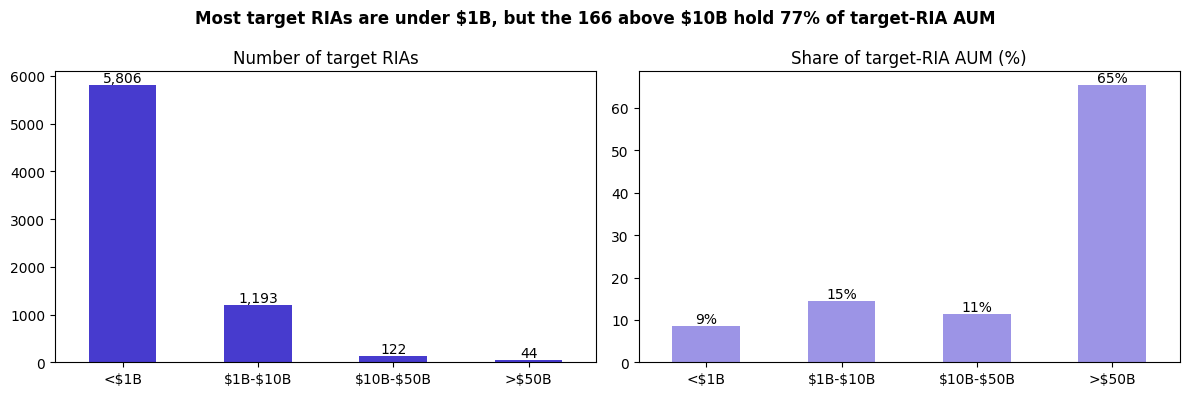

In [ ]:
#@title
wm_seg = latest[wmask].groupby("segment", observed=False).agg(firms=("crd", "count"), aum=("aum", lambda x: x.sum() / 1e12))
big = wm_seg.loc[["$10B-$50B", ">$50B"]]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
wm_seg.firms.plot.bar(ax=ax[0], color="#473BCE"); ax[0].set_title("Number of target RIAs")
for i, v in enumerate(wm_seg.firms): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
share = wm_seg.aum / wm_seg.aum.sum() * 100
share.plot.bar(ax=ax[1], color="#9C94E6"); ax[1].set_title("Share of target-RIA AUM (%)")
for i, v in enumerate(share): ax[1].text(i, v, f"{v:.0f}%", ha="center", va="bottom")
for a in ax: a.set_xlabel(""); a.tick_params(axis="x", rotation=0); a.set_xticklabels([l.replace("$", r"\$") for l in LABELS])
fig.suptitle(f"Most target RIAs are under \\$1B, but the {int(big.firms.sum())} above \\$10B hold {big.aum.sum() / wm_seg.aum.sum():.0%} of target-RIA AUM",
             fontweight="bold")
plt.tight_layout(); plt.show()

# 3. **Q2a - Who are the fastest-growing firm**

*Annual AUM growth over 3 years (main view), with 1- and 5-year views below. Organic growth only: firms that grew by acquisition or re-registration are listed separately.

**Key takeaways**


* **Sustained growth at scale:** multi-billion-dollar target RIAs compounding at 60-70%+ a year (Waverly, Arkadios, Apella, Pathstone, Merit). Growth 50+ percentage points above the segment median shows this isn't just the market.

* **Clear inorganic growth through acquisition.** Firms that grew by acquisition or consolidation (Focus Partners, Osaic, Cetera) are integrating acquired teams, each with its own workflows and tech stack. See Section 7.2.

**Median growth rates:**
- +\$50B = ~13%
- \$10–50B = ~12%
- \$1–10B = ~15%
- <\$1B = ~13%


In [ ]:
#@title
show(fast_wm[3], "Fastest-growing target RIAs: annual AUM growth over 3 years (FY2022→FY2025), top 5 per segment",
     cols=["segment", "firm_name", "channel", "state", "aum_start", "aum_end", "aum_cagr", "excess_growth"], n=5, sort="aum_cagr")

Segment,Firm,Channel,State,AUM at start ($B),AUM FY2025 ($B),AUM growth / yr,vs segment median
>$50B,Pathstone,Independent RIA,NJ,24.8,110.3,64%,+51 pts
>$50B,MAI Capital Management,Independent RIA,OH,15.8,52.1,49%,+35 pts
>$50B,Cresset Asset Management,Independent RIA,IL,24.6,78.9,47%,+34 pts
>$50B,IEQ Capital,Independent RIA,CA,18.5,56.8,45%,+32 pts
>$50B,Cerity Partners,Independent RIA,NY,53.3,161.7,45%,+31 pts
$10B-$50B,Waverly Advisors,Independent RIA,AL,5.8,29.9,73%,+61 pts
$10B-$50B,Apella Wealth,Independent RIA,CT,2.5,11.1,65%,+53 pts
$10B-$50B,Merit Financial Advisors,Dual-registered (BD),GA,5.5,23.9,63%,+51 pts
$10B-$50B,Summit Financial,Independent RIA,NJ,6.2,22.5,54%,+42 pts
$10B-$50B,Apollon Wealth Management,Independent RIA,SC,3.4,11.6,51%,+39 pts


In [ ]:
#@title
collapsible("Show the 1-year and 5-year views",
    show(fast_wm[1], "1-year AUM growth (FY2024→FY2025), top 5 per segment", cols=["segment", "firm_name", "channel", "state", "aum_start", "aum_end", "aum_cagr", "excess_growth"], n=5, sort="aum_cagr"),
    show(fast_wm[5], "Annual AUM growth over 5 years (FY2020→FY2025), top 5 per segment", cols=["segment", "firm_name", "channel", "state", "aum_start", "aum_end", "aum_cagr", "excess_growth"], n=5, sort="aum_cagr"))

Segment,Firm,Channel,State,AUM at start ($B),AUM FY2025 ($B),AUM growth / yr,vs segment median
>$50B,Focus Partners Wealth,Independent RIA,MO,95.9,181.9,90%,+75 pts
>$50B,Savant Wealth Management,Independent RIA,IL,29.6,55.6,88%,+73 pts
>$50B,MAI Capital Management,Independent RIA,OH,29.6,52.1,76%,+61 pts
>$50B,IEQ Capital,Independent RIA,CA,35.4,56.8,60%,+45 pts
>$50B,Cetera Investment Advisers,Independent RIA,IL,163.8,256.8,57%,+42 pts
$10B-$50B,Apella Wealth,Independent RIA,CT,4.7,11.1,135%,+121 pts
$10B-$50B,Merit Financial Advisors,Dual-registered (BD),GA,10.6,23.9,126%,+112 pts
$10B-$50B,&partners,Dual-registered (BD),TN,14.1,30.3,114%,+100 pts
$10B-$50B,Alphacore Capital,Independent RIA,CA,6.1,13.0,114%,+100 pts
$10B-$50B,Farther,Independent RIA,CA,7.5,16.0,113%,+99 pts


In [ ]:
#@title
show(inorganic_wm, "Grew by acquisition or consolidation (inorganic), 3 years: target RIAs, top 5 per segment",
     cols=["segment", "firm_name", "channel", "aum_start", "aum_end", "aum_cagr", "adv_start", "adv_end"], sort="aum_cagr")

Segment,Firm,Channel,AUM at start ($B),AUM FY2025 ($B),AUM growth / yr,Advisors at start,Advisors FY2025
>$50B,Focus Partners Wealth,Independent RIA,18.8,181.9,113%,215,"1,025"
>$50B,Osaic Wealth,Dual-registered (BD),29.5,234.9,100%,"2,075","7,143"
>$50B,Cetera Investment Advisers,Independent RIA,33.4,256.8,97%,"2,788","9,049"
>$50B,RBC Capital Markets,Dual-registered (BD),183.5,310.4,19%,"2,024","5,908"
>$50B,Empower Advisory Group,Independent RIA,116.2,195.4,19%,843,"6,138"
$10B-$50B,Osaic Advisory Services,Independent RIA,4.6,15.5,50%,119,344
$10B-$50B,Integrated Wealth Concepts,Independent RIA,7.5,23.6,47%,178,491
$10B-$50B,Evoke Advisors,Independent RIA,10.2,17.3,19%,19,25
$10B-$50B,SCS Capital Management,Independent RIA,29.0,48.7,19%,35,99
$10B-$50B,Rockefeller Capital Management,Independent RIA,22.7,36.8,18%,122,372


# 4. **Q2b - Which firms are capacity-strained?**

*FY2025 AUM and clients per advisor, firms with 3+ advisors. For target RIAs, clients per advisor matters as much as AUM, because advisor time scales with relationships, not dollars.*

**Key takeaways**
* **Typical load:** a \$1B+ target RIA runs about \$120M-\$130M of AUM and 60-80 clients per advisor (dashed lines in the chart; median table below).
* **Different Strain Depending On the Firm:** High AUM per advisor with few clients (Circle Wealth, Prowell, First Manhattan) usually means ultra-high-net-worth or family-office models: concentration risk with high value clients and effort predominantly on reporting, research and investment excellence demonstration. High clients per advisor (William Blair & Company) means volume pain: meetings, follow-ups and compliance notes.

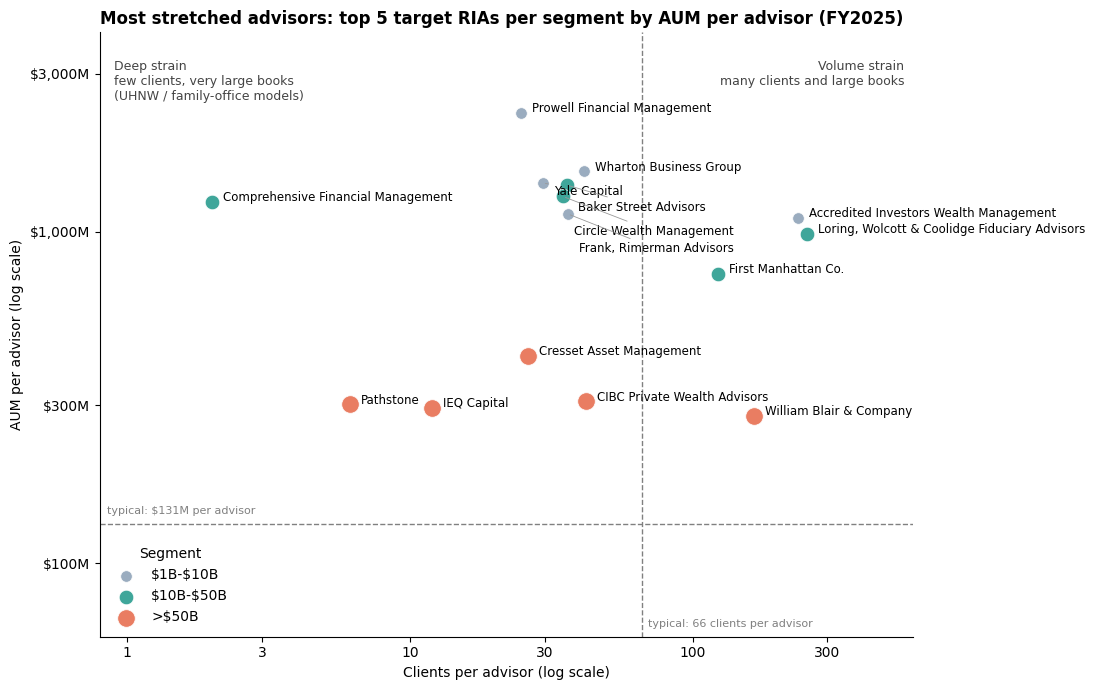

,Median AUM per advisor ($M),Median clients per advisor
Segment,,
<$1B,65,62
$1B-$10B,132,66
$10B-$50B,127,60
>$50B,107,79


In [ ]:
#@title
pool = cap[cap.wealth_manager & (cap.aum >= 1e9) & (cap.clients_per_advisor > 0)]
mx, my = pool.clients_per_advisor.median(), pool.aum_per_advisor.median() / 1e6     # typical load across all $1B+ target RIAs
d = (pool.sort_values("aum_per_advisor", ascending=False).groupby("segment", observed=True).head(5)).copy()   # same firms as the table
d["apa"] = d.aum_per_advisor / 1e6
COLS = {"$1B-$10B": "#8FA3B8", "$10B-$50B": "#2A9D8F", ">$50B": "#E76F51"}
SIZE = {"$1B-$10B": 70, "$10B-$50B": 110, ">$50B": 160}
fig, ax = plt.subplots(figsize=(11, 7))
for s, col in COLS.items():
    x = d[d.segment == s]
    ax.scatter(x.clients_per_advisor, x.apa, s=SIZE[s], color=col, alpha=0.9, edgecolor="white", linewidth=0.6,
               label=s.replace("$", chr(92) + "$"))
ax.set_xscale("log"); ax.set_yscale("log"); ax.minorticks_off()
ax.set_xticks([1, 3, 10, 30, 100, 300]); ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
yt = [30, 100, 300, 1000, 3000]; ax.set_yticks(yt); ax.set_yticklabels([f"\\${t:,}M" for t in yt])
ax.set_xlim(0.8, 600); ax.set_ylim(60, 4000)
ax.axvline(mx, ls="--", color="grey", lw=1); ax.axhline(my, ls="--", color="grey", lw=1)
ax.text(mx * 1.05, 64, f"typical: {mx:.0f} clients per advisor", fontsize=8, color="grey")
ax.text(0.85, my * 1.07, f"typical: \\${my:.0f}M per advisor", fontsize=8, color="grey")
ax.text(0.9, 3300, "Deep strain\nfew clients, very large books\n(UHNW / family-office models)", fontsize=9, color="#444", va="top")
ax.text(560, 3300, "Volume strain\nmany clients and large books", fontsize=9, color="#444", va="top", ha="right")
# Place labels so they don't overlap: work in screen pixels, push a label down until it clears those already placed
fig.canvas.draw(); placed = []; px2pt = 72 / fig.dpi
for _, r in d.assign(name=d.firm_name.map(nice_name)).sort_values("apa", ascending=False).iterrows():
    x0, y0 = ax.transData.transform((r.clients_per_advisor, r.apa)); w = 6.2 * len(r["name"]); y = y0 + 4
    while any(abs(y - py) < 13 and x0 < px + pw and px < x0 + w for px, py, pw in placed): y -= 13
    placed.append((x0, y, w))
    moved = abs(y - (y0 + 4)) > 1
    ax.annotate(r["name"], (r.clients_per_advisor, r.apa), xytext=(8 * px2pt / px2pt, (y - y0) * px2pt), textcoords="offset points",
                fontsize=8.5, va="center", arrowprops=dict(arrowstyle="-", color="#999", lw=0.6) if moved else None)
ax.set_xlabel("Clients per advisor (log scale)"); ax.set_ylabel("AUM per advisor (log scale)")
ax.set_title("Most stretched advisors: top 5 target RIAs per segment by AUM per advisor (FY2025)", fontweight="bold", loc="left")
ax.legend(title="Segment", loc="lower left", frameon=False)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()
med = cap_medians.copy(); med.index = med.index.astype(str); med.index.name = "Segment"
styled(med.rename(columns={"median AUM/advisor $M": "Median AUM per advisor ($M)", "clients_per_advisor": "Median clients per advisor"}),
       "Typical load per advisor: target RIAs with 3+ advisors (FY2025)", "{:,.0f}")


In [ ]:
#@title
show(cap_wm[cap_wm.segment.astype(str) != "<$1B"], "Highest AUM per advisor: target RIAs above $1B with 3+ advisors (FY2025), top 5 per segment",
     cols=["segment", "firm_name", "channel", "state", "aum", "advisors", "aum_per_advisor", "clients_per_advisor"], n=5, sort="aum_per_advisor")

Segment,Firm,Channel,State,AUM ($B),Advisors,AUM per advisor ($M),Clients per advisor
>$50B,Cresset Asset Management,Independent RIA,IL,78.9,187,422,26
>$50B,CIBC Private Wealth Advisors,Independent RIA,IL,67.8,220,308,42
>$50B,Pathstone,Independent RIA,NJ,110.3,365,302,6
>$50B,IEQ Capital,Independent RIA,CA,56.8,193,294,12
>$50B,William Blair & Company,Dual-registered (BD),IL,64.3,231,278,165
$10B-$50B,Baker Street Advisors,Independent RIA,CA,20.8,15,"1,385",36
$10B-$50B,Circle Wealth Management,Independent RIA,NJ,14.1,11,"1,279",35
$10B-$50B,Comprehensive Financial Management,Independent RIA,CA,18.5,15,"1,235",2
$10B-$50B,"Loring, Wolcott & Coolidge Fiduciary Advisors",Independent RIA,MA,12.8,13,987,253
$10B-$50B,First Manhattan Co.,Independent RIA,NY,38.1,51,747,123


# 5. **Which RIAs appear under-staffed?**

*Staffing gap = annual AUM growth minus annual growth in advisor headcount. A positive gap means each advisor carries more AUM every year. Firms need at least 3 advisors at the start; acquisitions are excluded.*

**Key takeaways**
* **Almost entire data set is understaffed with** 92% of \$1B+ target RIAs sit above the dashed line in the chart; median AUM growth of 17.9% a year vs 4.6% for advisors.
* **The clearest cases** grew AUM 50-70% a year with flat or falling advisor headcount (Wiss, Facet, Arkadios, Kingswood). They have the budget, and the strongest need for more leverage per advisor.

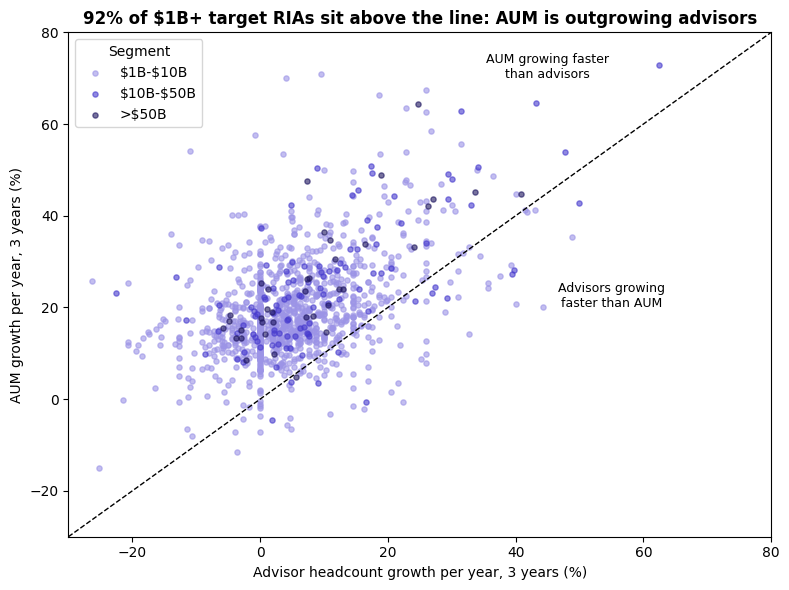

1,191 target RIAs above $1B · median AUM growth 17.9% a year vs advisor growth 4.6%


In [ ]:
#@title
fig, ax = plt.subplots(figsize=(8, 6))
for s, c in zip(LABELS[1:], ["#9C94E6", "#473BCE", "#1E1660"]):
    d = w3[w3.segment == s]; ax.scatter(d.advisor_cagr * 100, d.aum_cagr * 100, s=14, alpha=.6, label=s.replace("$", r"\$"), color=c)
lim = [-30, 80]; ax.plot(lim, lim, "k--", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.text(45, 70, "AUM growing faster\nthan advisors", ha="center", fontsize=9); ax.text(55, 20, "Advisors growing\nfaster than AUM", ha="center", fontsize=9)
ax.set_xlabel("Advisor headcount growth per year, 3 years (%)"); ax.set_ylabel("AUM growth per year, 3 years (%)")
ax.set_title(f"{(w3.staffing_gap > 0).mean():.0%} of \\$1B+ target RIAs sit above the line: AUM is outgrowing advisors", fontweight="bold")
ax.legend(title="Segment"); plt.tight_layout(); plt.show()
print(f"{len(w3):,} target RIAs above $1B · median AUM growth {w3.aum_cagr.median():.1%} a year vs advisor growth {w3.advisor_cagr.median():.1%}")

In [ ]:
#@title
show(gap_wm[3], "Most under-staffed target RIAs: 3 years (FY2022→FY2025), top 5 per segment", cols=["segment", "firm_name", "channel", "aum_end", "aum_cagr", "advisor_cagr", "staffing_gap", "adv_start", "adv_end"], n=5, sort="staffing_gap")

Segment,Firm,Channel,AUM FY2025 ($B),AUM growth / yr,Advisor growth / yr,Staffing gap,Advisors at start,Advisors FY2025
>$50B,Cresset Asset Management,Independent RIA,78.9,47%,7%,+40 pts,151,187
>$50B,Pathstone,Independent RIA,110.3,64%,25%,+40 pts,188,365
>$50B,MAI Capital Management,Independent RIA,52.1,49%,19%,+30 pts,137,230
>$50B,CWM,Independent RIA,50.6,36%,10%,+26 pts,354,472
>$50B,MML Investors Services,Dual-registered (BD),115.6,25%,0%,+25 pts,"4,951","4,961"
$10B-$50B,United Capital Financial Advisors,Independent RIA,24.6,23%,-23%,+46 pts,349,162
$10B-$50B,NewEdge Advisors,Independent RIA,43.2,50%,9%,+42 pts,398,515
$10B-$50B,OnePoint BFG Wealth Partners,Independent RIA,15.1,27%,-13%,+40 pts,159,104
$10B-$50B,Callan Family Office,Independent RIA,10.2,42%,5%,+37 pts,13,15
$10B-$50B,AE Wealth Management,Independent RIA,49.8,37%,0%,+37 pts,446,448


In [ ]:
#@title
collapsible("Show the 1-year and 5-year views",
    show(gap_wm[1], "1 year (FY2024→FY2025), top 5 per segment", cols=["segment", "firm_name", "channel", "aum_end", "aum_cagr", "advisor_cagr", "staffing_gap", "adv_start", "adv_end"], n=5, sort="staffing_gap"),
    show(gap_wm[5], "5 years (FY2020→FY2025), top 5 per segment", cols=["segment", "firm_name", "channel", "aum_end", "aum_cagr", "advisor_cagr", "staffing_gap", "adv_start", "adv_end"], n=5, sort="staffing_gap"))

Segment,Firm,Channel,AUM FY2025 ($B),AUM growth / yr,Advisor growth / yr,Staffing gap,Advisors at start,Advisors FY2025
>$50B,Focus Partners Wealth,Independent RIA,181.9,90%,-2%,+92 pts,"1,050","1,025"
>$50B,MAI Capital Management,Independent RIA,52.1,76%,13%,+63 pts,204,230
>$50B,Mercer Global Advisors,Independent RIA,84.4,40%,-15%,+55 pts,741,632
>$50B,Savant Wealth Management,Independent RIA,55.6,88%,34%,+54 pts,178,238
>$50B,CWM,Independent RIA,50.6,50%,4%,+46 pts,456,472
$10B-$50B,Farther,Independent RIA,16.0,113%,1%,+112 pts,250,252
$10B-$50B,Steward Partners Investment Advisory,Dual-registered (BD),36.7,48%,-22%,+70 pts,397,310
$10B-$50B,Apella Wealth,Independent RIA,11.1,135%,66%,+69 pts,53,88
$10B-$50B,Merit Financial Advisors,Dual-registered (BD),23.9,126%,59%,+67 pts,144,229
$10B-$50B,Waverly Advisors,Independent RIA,29.9,85%,30%,+56 pts,152,197


# 6. Consolidated findings: a prioritised Nevis target list (\$10B+)
Every US target RIA above \$10B with 5+ advisors is scored on three signals:

| Signal | What it shows | How it is measured |
|---|---|---|
| **3-year annual AUM growth** | Which firms are growing the fastest | Annual AUM growth, FY2022→FY2025 |
| **AUM per advisor** | Which firms' advisors need support today | FY2025 AUM ÷ advisors |
| **3-year staffing gap** | Which firms are on track for the highest capacity constraint | Annual AUM growth minus annual advisor-headcount growth, FY2022→FY2025 |

**Nevis score (0–100):** for each signal, every firm is ranked against the other firms in its own segment and given a percentile (0 = lowest in the segment, 100 = highest). The Nevis score is the simple average of the three percentiles, with equal weights. A score of 90 means that, on average across the three signals, the firm ranks in the top 10% of its segment. Scores rank firms within a segment, so they are not comparable across segments.


In [ ]:
#@title
big_targets = targets[targets.segment.astype(str).isin([">$50B", "$10B-$50B"])]
n50, n10 = (t.segment.astype(str) == ">$50B").sum(), (t.segment.astype(str) == "$10B-$50B").sum()
show(big_targets, f"Prioritised Nevis targets: top 10 per segment by Nevis score (scored against {n50} firms above $50B and {n10} at $10B-$50B)",
     cols=["segment", "firm_name", "channel", "website", "aum_end", "aum_cagr", "aum_per_advisor", "staffing_gap", "adv_end", "nevis_score"], sort="nevis_score")


Segment,Firm,Channel,Website,AUM FY2025 ($B),AUM growth / yr,AUM per advisor ($M),Staffing gap,Advisors FY2025,Nevis score
>$50B,Cresset Asset Management,Independent RIA,www.cressetpartners.com,78.9,47%,422,+40 pts,187,94
>$50B,Pathstone,Independent RIA,www.pathstone.com,110.3,64%,302,+40 pts,365,93
>$50B,Focus Partners Wealth,Independent RIA,www.focuspartners.com,181.9,113%,177,+45 pts,"1,025",88
>$50B,MAI Capital Management,Independent RIA,www.mai.capital,52.1,49%,227,+30 pts,230,88
>$50B,CWM,Independent RIA,www.carsonwealth.com,50.6,36%,107,+26 pts,472,72
>$50B,Savant Wealth Management,Independent RIA,www.savantwealth.com,55.6,44%,234,+17 pts,238,72
>$50B,Osaic Wealth,Dual-registered (BD),www.osaic.com,234.9,100%,33,+49 pts,"7,143",71
>$50B,IEQ Capital,Independent RIA,www.ieqcapital.com,56.8,45%,294,+12 pts,193,71
>$50B,Fisher Investments,Independent RIA,www.fisherinvestments.com,386.7,26%,198,+19 pts,"1,948",70
>$50B,Wells Fargo Advisors,Dual-registered (BD),www.wellsfargo.com,252.3,35%,107,+24 pts,"2,366",69


**How to use this list.** The score is a prioritisation aid, not a verdict:
* **\$50B+ (Enterprise):** Cresset, Pathstone, Focus Partners, MAI, Savant, Carson, IEQ and Fisher combine scale, strong growth and rising AUM per advisor. Osaic and Wells Fargo Advisors are a different motion: very large networks with low AUM per advisor, where the opportunity is giving thousands of independent advisors consistent tooling.
* **\$10B-\$50B:** Callan Family Office, Aptus, RWA, Clearstead, Merit, Apella, Apollon and NewEdge are fast-growing aggregators, multi-office firms or family offices, an ideal mid-market Enterprise wedge.
* **Next step to sharpen it:** add tech-stack signals and recent M&A announcements, then validate the top 20 with account research before outreach.

# 7. Additional supporting data

## 7.1 Which Custodians Should Nevis Focus On

*Source: Schedule D 5.K(3), each firm's latest filing to December 2024. Firms list every custodian holding 10%+ of their separately managed account AUM, so a firm can list several and columns add up to more than 100%.*

**Key takeaways**
* **Small Number of Custodians:** asset managers (all RIAs >\$50B) custody with BNY, State Street and Northern Trust. Target RIAs custody overwhelmingly with **Schwab and Fidelity**, plus Pershing.
* **Schwab and Fidelity each serve over half of \$10B+ target RIAs**, and Schwab ~64% of \$1B-\$10B firms. Schwab's investment in Nevis aligns with this.

*Caveat: custodians are reported only if they hold ≥10% of a firm's separately managed account AUM, and come from filings up to Dec 2024.*

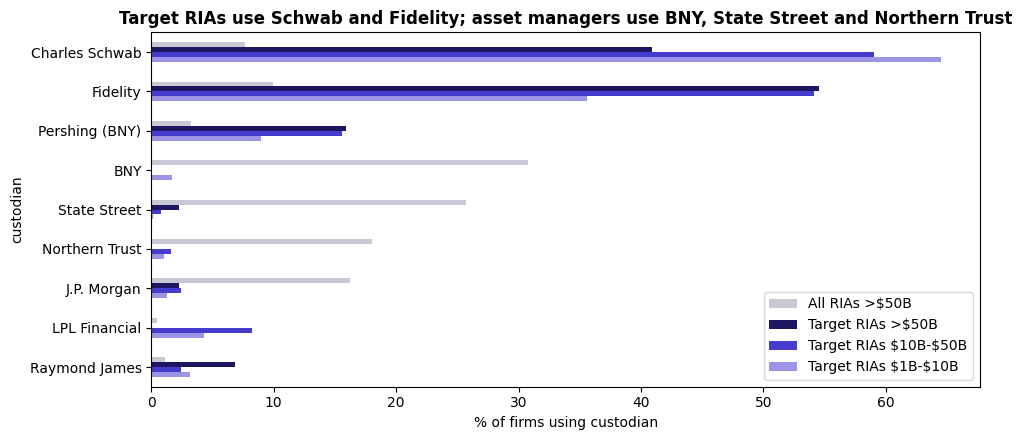

In [ ]:
#@title
fig, ax = plt.subplots(figsize=(10, 4.5))
views = ["All RIAs >$50B", "Target RIAs >$50B", "Target RIAs $10B-$50B", "Target RIAs $1B-$10B"]
top = ["Charles Schwab", "Fidelity", "Pershing (BNY)", "BNY", "State Street", "Northern Trust", "J.P. Morgan", "LPL Financial", "Raymond James"]
mat = pd.DataFrame({v: cust_tables[v][0].reindex(top).share_of_firms.fillna(0) * 100 for v in views})
mat.rename(columns=lambda c: c.replace("$", r"\$")).plot.barh(ax=ax, color=["#C9C9D6", "#1E1660", "#473BCE", "#9C94E6"]); ax.invert_yaxis()
ax.set_xlabel("% of firms using custodian"); ax.set_title("Target RIAs use Schwab and Fidelity; asset managers use BNY, State Street and Northern Trust", fontweight="bold"); plt.tight_layout(); plt.show()

## 7.2 Potential PE consolidation:

nearly half of \$10B+ target RIAs have a new owner since 2020. While some of these come from entity name transfers, the vast majority are through consolidation in the market. Tech rationalization & efficiency gains are often the primary levers PE buyers use. Nevis represents an exceptionally good option for PE firms looks to check both these boxes.

| Signal | Source | What it indicates |
|---|---|---|
| **New controlling entity since 2020** | Schedules A/B: an entity (not an individual) with 25%+ ownership or control, acquired 2020 or later | Sale to a PE sponsor, strategic acquirer or new holding structure |
| **Likely PE-backed (estimated)** | **Not a Form ADV field.** Estimated flag: the new controlling entity's name looks like an investment vehicle (L.P., Partners, Equity, Investors, Aggregator, Co-Invest, Fund) and does not share a name with the firm itself | Financial-sponsor ownership, typically with a buy-and-build (roll-up) strategy |
| **Succession since 2020** | Schedule D Section 4 | The firm took over another registered adviser's business |
| **Ownership layers** | Count of Schedule B indirect owners | Complex holding structures typical of sponsor-backed platforms |

**Key takeaways**
* **Ownership change is concentrated at the top:** nearly half of \$10B+ target RIAs have a new controlling entity since 2020, vs about a quarter of \$1B-\$10B firms.
* **PE-backed platforms** (Focus Partners and SCS/CD&R, Hightower/THL, Mariner/Leonard Green, Cerity/Genstar) are executing buy-and-build strategies.

*Caveat: the PE flag is a name-based heuristic. New owners named "Holdings" or "Holdco" (e.g. Creative Planning's new owners) count as ownership change but not as PE.*


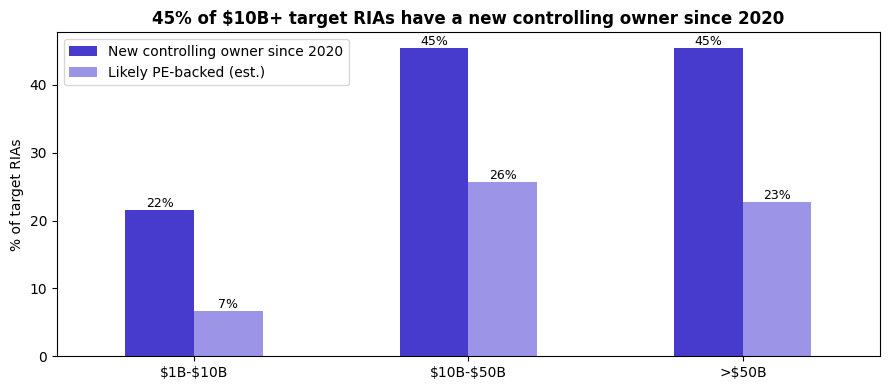

In [ ]:
#@title
o = own_summary[["new_controlling_entity", "likely_pe_sponsor"]] * 100
o.index = [str(i).replace("$", r"\$") for i in o.index]
fig, ax = plt.subplots(figsize=(9, 4))
o.rename(columns={"new_controlling_entity": "New controlling owner since 2020", "likely_pe_sponsor": "Likely PE-backed (est.)"}).plot.bar(ax=ax, color=["#473BCE", "#9C94E6"])
for cont in ax.containers: ax.bar_label(cont, fmt="%.0f%%", fontsize=9)
big = own[own.aum >= 10e9].new_controlling_entity_since_2020.fillna(False).astype(bool).mean()
ax.set_ylabel("% of target RIAs"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
ax.set_title(f"{big:.0%} of \\$10B+ target RIAs have a new controlling owner since 2020", fontweight="bold")
plt.tight_layout(); plt.show()

# 8. Process

## 8.1 Key terms and data dates
| Term | Meaning in this notebook |
|---|---|
| **AUM** | Regulatory assets under management as filed on Form ADV (Item 5.F) |
| **Target RIA** | An RIA Nevis would sell to: US-headquartered, 50%+ of AUM from individuals and high-net-worth clients, offers financial planning, and no more than 500 clients per advisor (broker-dealers with 100+ IARs, e.g. Merrill, also qualify). Asset managers, fund advisers, robo platforms and non-US firms are excluded; wirehouses are kept |
| **Independent RIA / Dual-registered (BD)** | Dual-registered firms are also broker-dealers (wirehouses such as Morgan Stanley, networks such as LPL or Edward Jones) |
| **Advisors** | Staff performing investment advisory functions (Form ADV Item 5.B(1)) |
| **Annual growth** | Compound annual growth rate (CAGR) between two September filings |
| **Staffing gap** | Annual AUM growth minus annual advisor-headcount growth, in percentage points (pts). Positive = each advisor carries more every year |
| **Organic / inorganic** | Inorganic = growth by acquisition or re-registration (AUM up 2.5x+ or advisors doubled in one year, or a reported succession). Ranked separately |
| **Segment** | FY2025 AUM band: under \$1B, \$1–10B, \$10–50B, over \$50B |

| Data | As of | Used in |
|---|---|---|
| AUM, clients, headcount (latest) | **FY2025**, from the SEC's September 2026 file | Sections 2–6 |
| Growth history | FY2020–FY2025 (September 2021–2026 files) | Sections 3, 5, 6 |
| Firm name, location, website | November 2026 file (most current) | All tables |
| Custodians and ownership | Each firm's latest filing to December 2024 (SEC bulk archive) | Section 7 |


## 8.2 How the data was built

| Step | What was done | Why |
|---|---|---|
| **1. Source** | Seven SEC monthly roster files: **September 2021–2026** for metrics, **November 2026** for firm names, addresses and websites | Firms only have to refresh AUM, clients and headcount once a year (the annual amendment, Form ADV General Instruction 4), so one September file per year captures every firm's latest annual figures. **CHECK V12:** 97.4% of firms are unchanged Sep→Nov 2026. Name, address and website must be updated promptly, so the latest file holds them. |
| **1b. Bulk archive** | SEC bulk Form ADV archive (filings to Dec 2024): custodians (Schedule D 5.K(3)), owners (Schedules A/B), successions (Schedule D 4), every listed website (Schedule D 1.I) | Not in the monthly roster. Each firm's latest filing to Dec 2024 is used, a year older than the FY2025 metrics. |
| **2. Standardise** | Map each file (262 columns to 2022, 448 from 2023) to the brief's fields: SEC# (1.D), CRD# (1.E), name/city/state (1.B, 1.F), website (1.I), AUM (5.F(2)(c)), clients (5.D), employees (5.A), advisors (5.B(1)) | Core fields are stable across the layout change (**CHECK V1**) |
| **3. Fix websites** | Prefer the most recent non-social site that matches the firm's name, from all filings | The roster holds one address per firm, often a social profile (Beacon Pointe shows Pinterest) |
| **4. Firm table** | One row per firm per year, linked by **CRD#** | CRD# stays constant through renames (**CHECK V11**) |
| **5. Classify** | **Target RIA** = US-headquartered, 50%+ of AUM from individuals/HNW, offers financial planning, at most 500 clients per advisor (or a broker-dealer with 100+ IARs, e.g. Merrill). Tagged **Independent RIA** vs **Dual-registered (broker-dealer)** | Removes asset managers, fund advisers, robo/TAMP platforms and non-US firms; keeps wirehouses (**CHECK V19**) |
| **6. Measure** | Growth = CAGR between Septembers; capacity = AUM and clients per advisor; staffing gap = AUM CAGR − advisor CAGR | Computed once in the analysis engine, then independently recomputed (**CHECK V16**) |

**Labelling:** a September file holds AUM as of each firm's last fiscal year end, so the **Sep 2026 file = FY2025** and results are labelled FY2020–FY2025.

**Rules that keep the rankings honest**
* **Minimum starting AUM by segment** (\$100M / \$200M / \$2B / \$10B), so a small firm re-registering can't "win" a larger segment.
* **Inorganic / step-change flag:** AUM up more than 2.5x or advisors more than doubled in a year, or a reported succession. These are acquisitions or roll-ups and are ranked separately.
* **Headcount reclassification flag:** advisors down more than 60% in a year (e.g. Vanguard 301 → 19) is a change in how the form was answered, not attrition. Excluded.
* **Segment = FY2025 AUM**, so firms are compared with today's peers.

**Limitations:** SEC-registered advisers only (state-registered firms, generally under \$100M, are excluded); growth is nominal and includes market returns; custodian and ownership data run to Dec 2024; advisors (5.B(1)) include research staff; the target-RIA definition is a rules-based proxy.


In [ ]:
#@title
print("SEC source files used (firms and columns per snapshot)")
display(sources_tbl)


SEC source files used (firms and columns per snapshot)


,firms,columns
2021-09,14638,262
2022-09,15362,262
2023-09,15528,448
2024-09,15923,448
2025-09,16359,448
2026-09,17149,448
2026-11,17263,448


## 8.3 Data checks: integrity of the data and accuracy of the calculations
Every check below runs automatically in the pipeline cell just before Section 2, before any result is shown, and is labelled `CHECK Vn` in the code. The full results table is at the end of this section. **Critical** checks stop the notebook if they fail (bad data never reaches the analysis); **warnings** are reported and explained.

| ID | What it proves |
|---|---|
| V0 | Source files (7 snapshots + 2 bulk archives) are byte-identical to the ones analysed (size + SHA-256 fingerprint) |
| V1 | Every snapshot contains every Form ADV field the analysis uses, despite the 262 → 448 column change in 2023 |
| V2 | Firm counts are in a plausible range and grow steadily (no truncated or partial files) |
| V3 | Exactly one row per firm (CRD#) per snapshot, so no double counting |
| V4 | Identifiers are well-formed (SEC# = 801-XXXXX, CRD# numeric) |
| V5 | Numeric fields parse cleanly (commas, blanks, text), with no silent data loss |
| V6 | AUM identity holds: discretionary + non-discretionary = total (Item 5.F(2)) |
| V7 | AUM by client type (Item 5.D) sums to total AUM, as Form ADV requires |
| V8 | No negative AUM, client or headcount values |
| V9 | Advisor headcount ≤ total employees (Item 5.B(1) vs 5.A) |
| V10 | Total regulatory AUM reconciles with SEC-published industry totals (~\$125T-\$128T in 2023) |
| V11 | Firms link cleanly across years by CRD# (year-on-year match rate) |
| V12 | September vs November 2026 AUM is almost unchanged, validating the "AUM updates annually" design choice |
| V13 | Spot check vs the SEC's public IAPD profile: Beacon Pointe (the brief's example firm) |
| V14 | Segment counts add up to the full FY2025 universe (no firm dropped or double-counted) |
| V15 | No infinite or impossible values in any derived ratio or growth rate |
| V16 | Growth figures reproduce from raw: CAGR independently recomputed from source AUM for 600 random firms |
| V17 | Ranked lists respect their own rules (min starting AUM, inorganic and reclassified firms excluded) |
| V18 | Website coverage and confidence are reported (data-quality transparency) |
| V19 | Classification is right: known asset managers excluded; known target RIAs (incl. wirehouses) included |
| V20 | Bulk-archive extracts (custodians, ownership) link to ≥95% of \$1B+ target RIAs |
| V21 | Custodian names are standardised (Schwab, Fidelity, Pershing…) for ≥90% of custodian-held AUM |

V0-V13 test the **data**; V14-V21 test the **calculations** and derived classifications.

**Headline reconciliation:** firm counts and total regulatory AUM by snapshot.

In [ ]:
#@title
qc = panel.groupby("year").agg(firms=("crd", "nunique"), total_raum_trn=("aum", lambda x: x.sum() / 1e12),
                               median_aum_mn=("aum", lambda x: x.median() / 1e6), zero_aum=("aum", lambda x: (x == 0).sum()),
                               zero_advisors=("advisors", lambda x: (x == 0).sum()), missing_advisors=("advisors", lambda x: x.isna().sum()))
qc

,firms,total_raum_trn,median_aum_mn,zero_aum,zero_advisors,missing_advisors
year,,,,,,
2021,14638,111.82,358.62,690,176,1
2022,15362,128.15,390.30,651,177,1
2023,15528,125.23,353.78,652,177,1
2024,15923,128.34,380.58,689,151,1
2025,16359,144.04,403.72,628,128,1
2026,17149,177.01,419.42,629,133,1


Totals reconcile with published SEC figures (about \$125T to \$128T of regulatory AUM in 2023). The 2026 step-up is market-driven and concentrated in the largest asset managers (Vanguard, Fidelity, BlackRock, PIMCO). Zero-advisor and zero-AUM firms are kept in the counts but excluded from any ratio that divides by them.

In [ ]:
#@title
print(f"{(summary.result == 'PASS').sum()} PASS · {(summary.result == 'WARN').sum()} WARN · {(summary.result == 'FAIL').sum()} FAIL")
summary

22 PASS · 0 WARN · 0 FAIL


,check,result,detail
id,,,
V0,Source files byte-identical to analysed versions,PASS,9/9 files match size + SHA-256
V1,All required Form ADV fields present in all 7 ...,PASS,30 fields × 7 files; missing: none
V2,Firm counts plausible (13k-20k) and rising eac...,PASS,"2021: 14,638 → 2022: 15,362 → 2023: 15,528 → 2..."
V3,One row per CRD# in every snapshot,PASS,duplicate CRDs: 0
V4,SEC# = 801-XXXXX and CRD# numeric,PASS,"SEC# valid 100.00%, CRD# valid 100.00% (worst ..."
V5,Numeric fields parse without loss,PASS,140 field-snapshots checked; unparseable value...
V6,Discretionary + non-discretionary AUM = total AUM,PASS,holds for 100.00% of firms (worst snapshot)
V7,Client-type AUM (5.D) sums to total AUM (5.F),PASS,within 1% for 100.0% of firms (worst snapshot)
V8,"No negative AUM, clients or headcount",PASS,negative values: 0


## 8.4 Code quality and how AI was used
* **How to run:** Runtime → Run all (about 4 minutes in Colab). The first run downloads the SEC files and caches them; every table and chart is also saved in the notebook, so it can be read without running anything. Run all rebuilds every number from the raw SEC files, with no manual steps.
* **Clear structure:** settings → data pipeline → analysis engine → data checks (one collapsed cell just before Section 2, with a banner per step) → results (2–7) → explanation (8). Settings, thresholds and segment bands are defined once and reused; small named functions (`fetch`, `standardise`, `window`, `top_by_segment`, `check`, `show`) each do one job.
* **Fails loudly:** 22 labelled checks (`CHECK Vn`); critical ones stop the notebook before any result is shown.
* **Reproducible and reviewable:** cached downloads, SHA-256 file fingerprints, a fixed random seed, `requirements.txt`, and `nevis_ria_analysis.py` (the same notebook as plain text, so changes diff cleanly on GitHub).

**How AI was used.** Built with Claude (Anthropic) working agentically, with the author directing and checking each step. Claude browsed the SEC site and found the right files, mapped all 448 columns to the brief's fields, wrote and ran the pipeline, and surfaced data traps (one website per firm, re-registration "growth", robo platforms passing a naive filter, advisor-count reclassifications), each turned into an explicit rule. The judgement calls were made by the author: snapshot timing (grounded in Form ADV General Instruction 4), the target-RIA definition, thresholds and the commercial framing. Results were verified by the 22 checks, reconciliation to SEC totals, an IAPD spot check of Beacon Pointe, and web spot checks of target websites.


In [ ]:
#@title Save outputs: Excel workbook of every ranked list and the firm-year CSV (outputs/)
with pd.ExcelWriter(OUT / "nevis_ria_targets.xlsx") as xw:
    fmt(targets).to_excel(xw, sheet_name="Nevis targets", index=False)
    seg.reset_index().to_excel(xw, sheet_name="Segments", index=False)
    summary.reset_index().to_excel(xw, sheet_name="Data checks", index=False)
    for h in (1, 3, 5):
        fmt(top_by_segment(win[h], "aum_cagr", n=25, wealth_only=True, cols=G, organic=True)).to_excel(xw, sheet_name=f"Fastest growth {h}y (target RIAs)", index=False)
        fmt(top_by_segment(win[h], "staffing_gap", n=25, wealth_only=True, cols=S, organic=True)).to_excel(xw, sheet_name=f"Under-staffed {h}y (target RIAs)", index=False)
        fmt(top_by_segment(win[h], "aum_cagr", n=25, cols=G, organic=True)).to_excel(xw, sheet_name=f"Fastest growth {h}y (all)", index=False)
        fmt(top_by_segment(win[h], "staffing_gap", n=25, cols=S, organic=True)).to_excel(xw, sheet_name=f"Under-staffed {h}y (all)", index=False)
    fmt(top_by_segment(cap, "aum_per_advisor", n=25, cols=C)).to_excel(xw, sheet_name="Capacity (all)", index=False)
    fmt(top_by_segment(cap, "aum_per_advisor", n=25, wealth_only=True, cols=C)).to_excel(xw, sheet_name="Capacity (target RIAs)", index=False)
    pd.concat({k: v[0].head(15) for k, v in cust_tables.items()}).reset_index().to_excel(xw, sheet_name="Custodians", index=False)
    own.reset_index().to_excel(xw, sheet_name="Ownership change ($1B+ targets)", index=False)
    latest.drop(columns=["segment"]).assign(segment=latest.segment.astype(str)).to_excel(xw, sheet_name="Firm table (2026)", index=False)
print("Saved:", list(OUT.iterdir()))

Saved: [PosixPath('outputs/nevis_ria_targets.xlsx'), PosixPath('outputs/ria_firm_year_table.csv')]
